# Describing data by variable type

Exploratory data analysis (EDA) is the first look at a dataset before any test or model: which values occur, how often, and what looks wrong. This page recaps how to describe one variable at a time. The type of the variable decides which summaries and charts make sense, so we start there. Then we cover distributions, centre and spread, robust summaries for skewed data, and frequency tables.

All examples use the second course dataset: the **Berlin listings of Inside Airbnb** (snapshot of 26 June 2026, 12,776 listings, CC BY 4.0; prepare it with `uv run python case-study/prepare_airbnb.py`, see [case-study/README.md](../../../case-study/README.md)). Prices, sizes, districts and ratings raise the questions this session is about: what does a night cost, where, and which differences are real? The data were collected from public listing pages; host names and texts have been removed, and results are reported in aggregate. Session 4 found that listings with a minimum stay of 28 nights or more report prices that are not comparable with short stays, so price analyses here use the **6,701 short-stay listings with a price** and say so. Chart design follows on the [next page](02-lecture-chart-design.ipynb), relationships between two numeric variables in [03-lecture-relationships.ipynb](03-lecture-relationships.ipynb).

```mermaid
flowchart LR
    V["A variable"] --> Q{"What type?"}
    Q -->|"numeric, continuous"| N["histogram, box plot<br/>mean/median, SD/IQR"]
    Q -->|"numeric, count"| C["bar chart of counts<br/>median, quantiles, share of zeros"]
    Q -->|"ordinal"| O["bar chart in order<br/>median, shares per level"]
    Q -->|"nominal"| M["sorted bar chart<br/>frequency table, mode"]
    Q -->|"date/time"| T["line chart over time<br/>counts per period"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Variable types

### Concept

A **variable** is one column of a table: one property measured for every observation (here: every listing). Its **type** decides what arithmetic makes sense.

| Type | Meaning | Case-study example | Sensible summaries |
|---|---|---|---|
| **Nominal** (categorical) | categories without order | `room_type` (4 types), `district` (12), `neighbourhood` (138), `host_is_superhost` (yes/no) | counts, shares, mode |
| **Ordinal** | categories with an order but no fixed distance | the star rating a single guest gives (1 to 5) | counts, shares, median, quantiles |
| **Discrete numeric (count)** | whole numbers from counting | `accommodates` (guests), `bedrooms`, `number_of_reviews`, `minimum_nights` | median, quantiles, share of zeros, mean with care |
| **Continuous numeric** | measurements on a continuous scale | `price` (EUR per night), `latitude`, `longitude`, the average `review_scores_rating` | mean, median, SD, IQR |
| **Date/time** | a point in time | `first_review`, `last_review`, `month` in the monthly review counts | range, counts per day/month |

The listing `id` and the `host_id` look like numbers but are **codes**: listing 3176 is not "smaller" than listing 9991, and their mean means nothing. The average review score is a mean of ordinal star ratings; treating it as continuous is a convention that works because it averages many ratings, but it is bounded at 5 and crowded near the top.

A worked example on ordinal data: the mean of the star ratings 1, 5, 5 is 3.67. That number assumes the step from 1 to 2 stars is as large as the step from 4 to 5. For a rating scale this is a convention, not a fact. The median (5) and the share of 5-star ratings (2 of 3) need no such assumption.

### Why it matters

Software computes a mean for any column of numbers, including IDs and postal codes. The type tells you whether the result means anything. It also decides the test you choose later (see the [test decision table](06-lecture-testing-and-communicating.ipynb)) and how a feature enters a model (Session 6 onwards).

### How it works in Python

In [2]:
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
print(listings[["room_type", "district", "host_is_superhost", "accommodates", "price", "last_review"]].dtypes)
# room_type                    object   -> nominal (4 room types)
# district                     object   -> nominal (12 districts)
# host_is_superhost            object   -> nominal, binary (True/False, 16 missing)
# accommodates                  int64   -> count (guests)
# price                       float64   -> continuous (EUR per night)
# last_review          datetime64[ns]   -> date/time
print(listings["district"].nunique(), listings["neighbourhood"].nunique())       # 12 138
print(listings["id"].dtype)                                                      # int64: a code stored as a number

room_type                       str
district                        str
host_is_superhost            object
accommodates                  int64
price                       float64
last_review          datetime64[ns]
dtype: object
12 138
int64


### In practice

- Survey research distinguishes Likert items (ordinal) from scale scores; the European Social Survey documentation states the measurement level of every variable.
- Official statistics (Eurostat, Destatis) publish median rather than mean income because income is a skewed continuous variable.
- Statistical offices store regional codes (for example the German municipality key, *Amtlicher Gemeindeschlüssel*) as text with leading zeros, because they are codes, not quantities.

> **Warning.** **Numbers that are not quantities.** IDs, postal codes and encoded categories (1 = Berlin, 2 = Hamburg) look like numbers but are nominal. Keep them as strings or `category`; read as integers, postal code `01067` (Dresden) becomes `1067`, and `describe()` reports a meaningless mean of listing IDs.

## Distributions

### Concept

The **distribution** of a variable tells you which values occur and how often. Describe it by three properties:

- **centre**: a typical value (mean, median, mode);
- **spread**: how far values scatter around the centre (standard deviation, interquartile range);
- **shape**: symmetric or **skewed** (a long tail on one side), one peak (unimodal) or several (multimodal), gaps, spikes at round numbers.

A **histogram** cuts the value range into intervals (bins) and draws a bar for the number of observations in each. A **box plot** draws the quartiles as a box, the median as a line and points beyond 1.5 × IQR from the box as individual dots.

![Histogram of the price per night of short-stay listings on a linear and a logarithmic axis, with mean and median marked](../figures/skewed-distribution.png)

The nightly price is **right-skewed**: most short-stay listings cost between €80 and €330, a few several thousand euros. On a linear axis the long tail squeezes the bulk into the first bars. On a **logarithmic axis** equal distances stand for equal ratios (€10, €100, €1,000), and the shape becomes readable: roughly symmetric, with a peak around €150. The box plots in the code below add the obvious explanation for part of the spread: entire homes cost more than private rooms, and shared rooms least.

### Why it matters

Very different datasets can share the same mean and standard deviation. Anscombe's quartet (1973) and the Datasaurus Dozen (Matejka & Fitzmaurice, 2017) are built to show this. A histogram also reveals data problems that summaries hide: impossible values, gaps, spikes at default values, or a second population, such as the medium-term listings of Session 4.

### How it works in Python

6701 23.5
11 25


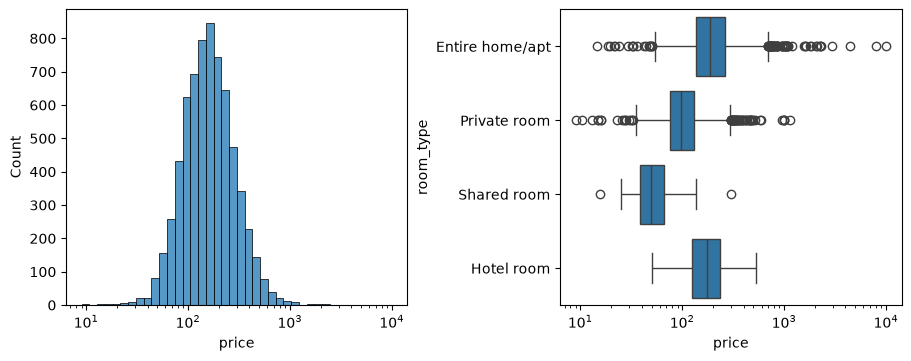

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]   # comparable prices (Session 4)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
sns.histplot(short, x="price", log_scale=True, bins=40, ax=left)                  # shape on a log axis
sns.boxplot(short, x="price", y="room_type", log_scale=True, ax=right)            # one box per group
print(len(short), round(short["price"].skew(), 1))   # 6701 23.5: extreme right skew (0 = symmetric)
print((short["price"] < 20).sum(), (short["price"] > 1000).sum())   # 11 25: look at these rows

### In practice

- Web performance teams (for example in Google's Web Vitals programme) look at the whole distribution of page-load times and report the 75th percentile, because the tail is what users notice.
- Hospital statistics show length of stay as a histogram: most patients leave within days, a few stay for months.
- Rent reports (for example Berlin's *Mietspiegel*) give ranges and medians of rents per square metre rather than a single average, because rents are skewed.

> **Tip.** Plot before you summarise. Try two or three bin widths: too few bins hide structure, too many show noise.

> 📖 **Read more:** [extras/01-exploratory-data-analysis.ipynb](extras/01-exploratory-data-analysis.ipynb) (Think Stats, chapter 1): a first exploration of a survey dataset from reading the file to validation, transformation and summary statistics.

## Centre and spread

### Concept

- The **mean** is the sum divided by the count: the balance point of the data. Every value pulls on it, so a long tail drags it towards the tail.
- The **median** is the middle value after sorting: half of the data lie below it.
- The **mode** is the most frequent value; it is the only centre for nominal data.
- The **standard deviation (SD)** is roughly the typical distance from the mean. It squares the distances, so large deviations dominate it.
- The **quartiles** Q1 and Q3 cut off the lowest and highest 25 %. The **interquartile range** IQR = Q3 − Q1 is the width of the middle half.

Worked example with five nightly prices: €80, €120, €150, €180 and €970. The mean is €1,500 / 5 = €300, but four of five listings cost less than €181. The median is €150. Remove the €970 listing and the mean drops to €132.50, while the median moves only from €150 to €135.

### Why it matters

A summary that is pulled by a few extreme values misleads every decision built on it. For skewed variables, report the median and IQR (or several quantiles), and give the mean only with this caveat.

### How it works in Python

In [4]:
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]

print(short["price"].agg(["mean", "median", "std"]).round(1).to_dict())
# {'mean': 193.7, 'median': 157.0, 'std': 217.0}
q1, q3 = short["price"].quantile([0.25, 0.75])
print(q1, q3, q3 - q1)                       # 107.0 232.0 125.0  -> IQR 125 EUR
print(listings[["accommodates", "minimum_nights", "number_of_reviews"]].describe().round(1).loc[["mean", "50%", "std", "max"]])
#       accommodates  minimum_nights  number_of_reviews
# mean           3.1            34.7               52.9
# 50%            2.0             3.0               11.0
# std            2.0            52.5              108.7
# max           16.0          1125.0             2832.0

{'mean': 193.7, 'median': 157.0, 'std': 217.0}
107.0 232.0 125.0
      accommodates  minimum_nights  number_of_reviews
mean           3.1            34.7               52.9
50%            2.0             3.0               11.0
std            2.0            52.5              108.7
max           16.0          1125.0             2832.0


The minimum stay shows why one centre is not always enough: the median is 3 nights and the mean 35, because the listings form two clusters (1–3 nights and exactly 92 nights; Session 4). No single number describes a variable with two peaks; say "six in ten listings accept stays of a week or less, a third require at least 92 nights".

### In practice

- The EU at-risk-of-poverty threshold is defined as 60 % of the national **median** equivalised income (Eurostat).
- Real-estate portals and statistical offices report median asking rents and house prices.
- Service-level agreements state percentiles (p50, p95, p99) of response times rather than means.

> **Caution.** **SD on skewed or clustered data.** The minimum stay has mean 35 nights and SD 52 nights. "Mean ± 2 SD" would suggest minimum stays from minus 70 to plus 140 nights; no stay is negative, and the most common values (1 and 92) are not near the mean at all. For skewed, bounded or clustered variables, describe spread with quantiles and shares instead.

> 📖 **Read more:** [extras/02-descriptive-statistics-and-t-test.ipynb](extras/02-descriptive-statistics-and-t-test.ipynb) (Microsoft Data Science for Beginners): mean, median, quartiles, the normal distribution and a confidence interval on the heights and weights of baseball players.

## Robust summaries

### Concept

A statistic is **robust** if a few extreme values cannot move it far. The **breakdown point** is the share of observations you can replace by arbitrary values before the statistic becomes arbitrary: 0 % for the mean (one huge value suffices), 50 % for the median.

Robust alternatives:

- **median** instead of mean;
- **IQR** or the **median absolute deviation (MAD)**, the median of |x − median|, instead of SD;
- the **trimmed mean**, which drops a fixed share (for example 10 %) at each end before averaging;
- **quantiles** (p1, p10, p90) to describe a tail directly.

### Why it matters

Real data contain recording errors, placeholder values and genuine extreme cases. In the listings, a handful of short-stay prices above €1,000 (up to €10,025 for a loft for seven guests) may be typing errors or prices meant to block bookings. Robust summaries describe the bulk of the data; comparing them with the classical ones shows how much the extremes matter. Session 4 used the same ideas to flag outliers; Session 6 applies them to regression.

### How it works in Python

In [5]:
import pandas as pd
from scipy import stats

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
price = listings.loc[listings["price"].notna() & listings["minimum_nights"].lt(28), "price"]

print(round(price.mean(), 1), price.median())                 # 193.7 157.0
print(round(stats.trim_mean(price, 0.1), 1))                  # 169.0: 10 % cut at each end
print(stats.median_abs_deviation(price))                      # 57.0: half the prices within 57 EUR of the median
print(price.quantile([0.1, 0.5, 0.9, 0.99]).round(0).to_dict())
# {0.1: 78.0, 0.5: 157.0, 0.9: 330.0, 0.99: 694.0}

rating = listings["review_scores_rating"].dropna()            # average of guests' 1-5 stars
print(rating.median(), round(stats.median_abs_deviation(rating), 2), round((rating == 5).mean(), 3), round((rating < 4).mean(), 3))
# 4.86 0.14 0.259 0.017: a quarter of rated listings have a perfect 5.0, under 2 % are below 4

193.7 157.0
169.0
57.0
{0.1: 78.0, 0.5: 157.0, 0.9: 330.0, 0.99: 694.0}
4.86 0.14 0.259 0.017


In plain words: "A short-stay night in Berlin costs €157 at the median; one listing in ten costs less than €78, one in ten more than €330." Three numbers describe the variable better than mean and SD, which are pulled up by a few extreme prices. The ratings are crowded at the top: a "4.5" is a below-average listing, which matters when you compare ratings later.

### In practice

- Economic statistics use trimmed-mean inflation measures; the Federal Reserve Bank of Dallas publishes a trimmed-mean PCE inflation rate.
- Laboratory medicine derives reference intervals from central percentiles of healthy populations.
- Sports judging (for example in diving and figure skating) has long dropped the highest and lowest scores before averaging.

> **Warning.** A small MAD does not always mean "little spread". If more than half of the values are identical, the MAD is 0; if half are in one tight cluster, it describes only that cluster. The minimum stay has MAD = 2 nights although 30 % of listings require 92. Always look at the share of the most common values as well.

## Frequency tables

### Concept

For categorical and ordinal variables, the summary is a **frequency table**: the count and the share (relative frequency) of each category. A **cross-tabulation** counts combinations of two categorical variables; it is the starting point for the chi-square test in block 2 ([06-lecture-testing-and-communicating.ipynb](06-lecture-testing-and-communicating.ipynb)).

Worked example: 8,846 of 12,776 listings are entire homes or flats, a share of 8,846 / 12,776 = 69.2 %.

### Why it matters

Shares make groups of different size comparable; counts show whether a share rests on 10 or 10,000 observations. Report both. A share of 100 % of shared rooms in a district means little if the district has one shared room.

### How it works in Python

In [6]:
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")   # reviews per listing and month

counts = listings["room_type"].value_counts()
shares = listings["room_type"].value_counts(normalize=True)
print(pd.DataFrame({"n": counts, "share": shares.round(3)}))
#                     n  share
# room_type
# Entire home/apt  8846  0.692
# Private room     3754  0.294
# Hotel room         89  0.007
# Shared room        87  0.007

# Cross-tabulation with row shares: room-type mix per district
print(pd.crosstab(listings["district"], listings["room_type"], normalize="index")
      .loc[["Mitte", "Pankow", "Neukölln", "Reinickendorf"], ["Entire home/apt", "Private room"]].round(3))
# room_type      Entire home/apt  Private room
# district
# Mitte                    0.720         0.258
# Pankow                   0.779         0.211
# Neukölln                 0.609         0.386
# Reinickendorf            0.551         0.438

hoods = listings["neighbourhood"].value_counts()
print(len(hoods), (hoods < 20).sum(), hoods.head(3).to_dict())
# 138 46 {'Alexanderplatz': 884, 'Frankfurter Allee Süd FK': 675, 'Tempelhofer Vorstadt': 568}

# Counts per month (date/time variable): reviews as a proxy for stays
per_month = monthly.groupby("month")["n_reviews"].sum()
print(per_month.loc[["2019-07-01", "2020-04-01", "2025-07-01"]].to_dict())
# {Timestamp('2019-07-01 ...'): 4865, Timestamp('2020-04-01 ...'): 285, Timestamp('2025-07-01 ...'): 13132}

                    n  share
room_type                   
Entire home/apt  8846  0.692
Private room     3754  0.294
Hotel room         89  0.007
Shared room        87  0.007
room_type      Entire home/apt  Private room
district                                    
Mitte                    0.720         0.258
Pankow                   0.779         0.211
Neukölln                 0.609         0.386
Reinickendorf            0.551         0.438
138 46 {'Alexanderplatz': 884, 'Frankfurter Allee Süd FK': 675, 'Tempelhofer Vorstadt': 568}
{Timestamp('2019-07-01 00:00:00'): 4865, Timestamp('2020-04-01 00:00:00'): 285, Timestamp('2025-07-01 00:00:00'): 13132}


The room-type mix differs by district: four in ten listings in Neukölln and Reinickendorf are private rooms, two in ten in Pankow. Any comparison of district prices must take this into account ([03-lecture-relationships.ipynb](03-lecture-relationships.ipynb)). The monthly review counts show the COVID collapse of April 2020 and strong growth since. Two cautions: a review is a proxy for a stay (not every guest writes one), and the file contains only listings that still exist in 2026, so older years are undercounted.

### In practice

- Customer-satisfaction reports (for example the American Customer Satisfaction Index) publish the share of each response category.
- Election results are frequency tables of votes per party, with counts and percentages.
- Clinical trial publications begin with "Table 1": frequencies and shares of patient characteristics per study arm.

> **Tip.** The neighbourhood has a **long tail**: 138 neighbourhoods, the largest with 884 listings, 46 with fewer than 20. Show the top of such a table and say how many categories are in the tail; shares computed for tiny groups jump around (Session 9 returns to such high-cardinality variables).

## Check your understanding

1. Classify `room_type`, `accommodates`, `review_scores_rating` and `last_review` by type and name one sensible summary for each.
2. The mean short-stay price is €194 and the median €157. What does this tell you about the shape of the distribution?
3. Why is "mean ± 2 SD" a poor description of the minimum stay? What would you report instead?
4. What is the breakdown point of the median, and what does it mean in plain words?
5. A district has a median price of €250, computed from 6 listings. How would you present this in a frequency table of districts?

## Further reading

- Downey, A. B. (2025). *Think Stats: Exploratory Data Analysis in Python* (3rd ed.), chapters 1–4. O'Reilly. Free online: <https://allendowney.github.io/ThinkStats/>
- Wilke, C. O. (2019). *Fundamentals of Data Visualization*, chapter 7 "Visualizing distributions: Histograms and density plots". O'Reilly. <https://clauswilke.com/dataviz/histograms-density-plots.html>
- Poldrack, R. A. (2023). *Statistical Thinking for the 21st Century*, chapter 4 "Summarizing data". <https://statsthinking21.github.io/statsthinking21-core-site/>
- Inside Airbnb. *Data assumptions* (how the data are collected and what they can and cannot show). <https://insideairbnb.com/data-assumptions/>